In [ ]:
from TP.entrega.alc import norma, producto_interno, QR_con_GS, arroba, svd_reducida
import numpy as np
import pandas as pd

El archivo object_points me da las coordenadas de referencia es decir (U, V, W) y lo que me pide el ejercicio a) es que elegir las coordenadas de la imagen convenientemente. Como sabemos cuales son las de referencia entonces elijo los puntos que concuerdan con la referencia es decir el extremo exterior sup. izq., el extremo exterior sup. der., el extremo exterior inf. der. y el extremo exterior inf. izq.

/home/linux/librerias/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


(1232, 1640, 3)


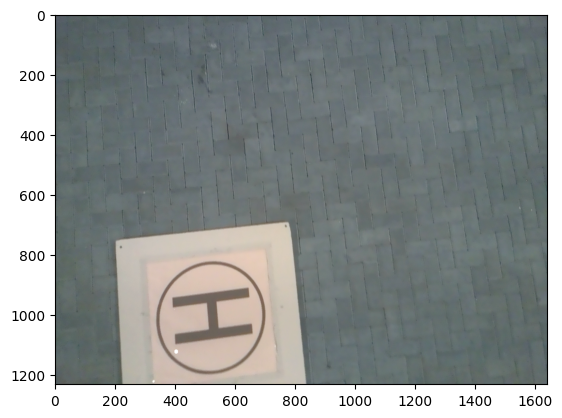

In [2]:
import cv2
import matplotlib.pyplot as plt

rgb = cv2.imread('../heli/row_00248.png')
plt.imshow(rgb)
print(rgb.shape)


Con esto ya tengo una referencia entonces jugamos un poco para ver que puntos puedo elegir, siguiendo el archivo chequeo_puntos_3d.ipynb y manteniendo el orden de object_points.csv.

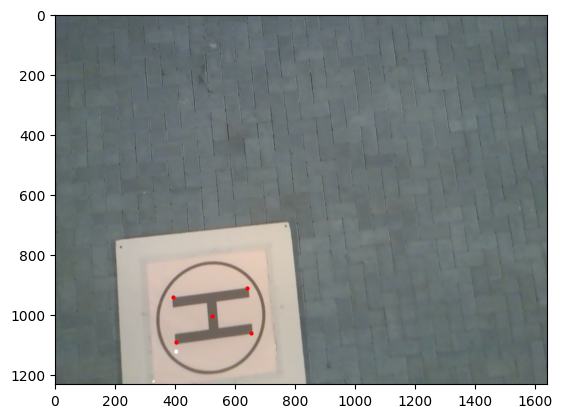

In [ ]:
plt.imshow(rgb)

u_v = np.array([[525, 1005],
               [405, 1090],
               [395, 940],
               [640, 910],
               [655, 1060]])

M_0 = np.array([[0, 0, 0], 
                [-0.175, 0.3, 0], 
                [0.175, 0.3, 0],
                [0.175, -0.3, 0],
                [-0.175, -0.3, 0]])

plt.plot(m_0[:, 0], m_0[:, 1], 'ro', markersize = 2)


Usamos $\mathbf{C}^2 = \|\mathbf{J}_0\|_2 - \|\mathbf{I}_0\|_2 - 2i \times \mathbf{I}_0 \times \mathbf{J}_0$ para calcular las raices.

In [ ]:
def calculoLambdaMu(I0, J0):
    # Podemos usar el metodo sqrt de numpy que esta permitido    
    C_2 = norma(J0, 2) - norma(I0, 2) - 2j * producto_interno(I0, J0)
    
    raiz = np.sqrt(C_2) # me da una sola raiz pero el ejercicio me pide las dos
    
    lammbda, mu = raiz
    
    return (lammbda, mu), (-lammbda, -mu)

In [ ]:
def calcularSalidaPOSIT(Is, Js, fx, m0, M0):
    # Is y Js son vectores
    # M_0 = [X_0, Y_0, Z_0]
    
    norma_Is = norma(Is, 2)
    norma_Js = norma(Js, 2)
    
    Z_0 = fx / norma_Is
    
    i = Is / norma_Is
    j = Js / norma_Js
    
    # hace falta un vector ortogonal a i y j que ya son ortogonales entre si
    # para saber quien es k teniendo en cuenta los laboratorios
    # podemos pensar en el producto vectorial, pero no tenemos dicha funcion e implementarla
    # resulta engorroso porque no tememos funcion determinante. Hacerla directo con el producto
    # interno tambien es dificil porque no vimos como resolver un sistema lineal sin estar triangulado.
    # Entonces, uso QR_con_GS y me armo una matriz A con i, j y (1, 0, 0). Como i y j ya son ortogonales
    # en Q van a ser los mismos y la tercer columna va a ser nuestro i deseado. Justamente, la Q va a ser
    # R que nos estan pidiendo
    
    A = np.array([i,j,[1,0,0]]).T
    
    Q, R_de_Q = QR_con_GS(A)
    
    k = Q[:, 2] 
    R = Q
    
    # Centramos las coordenadas de la imagen
    K = pd.read_csv('TP/heli/K.csv') 
    x_0 = m0[0] - K[0][2]
    y_0 = m0[1] - K[1][2]
    
    
    X_0 = (Z_0 / fx) * x_0
    Y_0 = (Z_0 / fx) * y_0
    
    # Trasladamos la camara para que M0 sea el origen
    T = np.array([X_0, Y_0, Z_0]) - arroba(R, M0)
    
    return i, j, k, Z_0, R, T 

In [10]:
def evaluarPose(R, t, obj_vecs, img_vecs, K):
    validos = len(obj_vecs)
    puntos_camara = []
    
    for vecs in obj_vecs:
        punto_camara = arroba(R, vecs) + t # [X_i, Y_i, Z_i]
        # Quiere decir que quedo detras de la camara. Descartamos la solucion
        if punto_camara[2] <= 0: 
            return 0, None    
            
        puntos_camara.append(punto_camara)
     
    # Ahora queremos ver donde va a parar ese punto en el pixel (en la foto)
    # Las proyecciones en los pixeles van a ser K multiplicado cada punto
    # dada en la seccion del modelo pinhole ecuacion (2)
    
    fx = K[0][0]
    fy = K[1][1]
    se = K[0][1]
    cu = K[0][2]
    cv = K[1][2]
    
    for punto in puntos_camara:
        X_i, Y_i, Z_i = punto
        u = fx * (X_i / Z_i) + se * (Y_i / Z_i) + cu
        v = fy * (Y_i / Z_i) + cv
        proyecciones.append(np.array([u, v]))
        
    # Una vez que tenemos la proyecciones, calculamos el RMS
    proyecciones = np.array(proyecciones) 
    img_vecs = np.array(img_vecs)
    
    rms = np.sqrt(np.mean((img_vecs - proyecciones)**2))

    return validos, rms
        
    

Tenemos que el conjunto de puntos de los objetos M0 nos lo dan en object_points que serian las coordenadas del mundo real de la imagen. Los m0 los dimos en el punto a) y son los correcpondientes a los M0 pero en la imagen. 
xi yi corresponden a mi que son los puntos de m0 que no son m0

In [ ]:
def aplicarPOSIT(obj_vecs, img_vecs, K, MaxIt, atol):
    # Devolvemos la pose de la camara R y t y vamos ajustando iterativamente
    
    M0 = obj_vecs[0]
    
    # Centralizamos los puntos de la imagen como en c)
    x_y = []
    for u, v in img_vecs:
        x = u - K[0][2]
        y = v - K[1][2]
        
        x_y.append([x, y])
        
    A = []
    for i in range(len(obj_vecs)):
        A.append(obj_vecs[i] - M_0)
    
    # Necesitamos el n que forma parte del nucleo pues An = 0
    # Lo obtenemos por SDV como el vector de asociado al valor 
    # singular 0
    _, _, Vt = svd_reducida(A)
    
    n = Vt[-1]
    
    e_i = 0